# Student Performance Advisor

### _Import libraries_

In [1]:
from pathlib import Path
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import SelectFromModel
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
RANDOM_STATE = 42
DATA_PATH = Path("../data/raw/StudentPerformanceFactors.csv")
TARGET = "Exam_Score"

RANDOM_STATE = 42
TEST_SIZE = 0.15
VALIDATION_SIZE = 0.15  

np.random.seed(RANDOM_STATE)
warnings.filterwarnings("ignore", category=FutureWarning)

ROOT_DIR = Path.cwd()
MODEL_DIR = Path("../models") / "machine learning models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Working directory:", ROOT_DIR.resolve())

Working directory: D:\AI 4\First Semester\Data science\Project\RAGentML_DS\notebooks


### _Load data_

In [3]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH.resolve()}\n"
        "Download the Kaggle CSV and put it in data/raw/StudentPerformanceFactors.csv"
    )

df = pd.read_csv(DATA_PATH)
print(f"Loaded: {DATA_PATH}")
print("Dataset shape:", df.shape)
display(df.head())

Loaded: ..\data\raw\StudentPerformanceFactors.csv
Dataset shape: (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


### _Explore data_

In [4]:
print("Columns:")
print(df.columns.tolist())

Columns:
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']


In [5]:
display(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

None

In [6]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Hours_Studied,6607.0,NaN,NaN,NaN,19.975329,5.990594,1.0,16.0,20.0,24.0,44.0
Attendance,6607.0,NaN,NaN,NaN,79.977448,11.547475,60.0,70.0,80.0,90.0,100.0
Parental_Involvement,6607,3,Medium,3362,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Access_to_Resources,6607,3,Medium,3319,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Extracurricular_Activities,6607,2,Yes,3938,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sleep_Hours,6607.0,NaN,NaN,NaN,7.02906,1.46812,4.0,6.0,7.0,8.0,10.0
Previous_Scores,6607.0,NaN,NaN,NaN,75.070531,14.399784,50.0,63.0,75.0,88.0,100.0
Motivation_Level,6607,3,Medium,3351,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Internet_Access,6607,2,Yes,6108,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tutoring_Sessions,6607.0,NaN,NaN,NaN,1.493719,1.23057,0.0,1.0,1.0,2.0,8.0


In [7]:
print("Missing values per column:")
display(df.isna().sum().sort_values(ascending=False))

Missing values per column:


Parental_Education_Level      90
Teacher_Quality               78
Distance_from_Home            67
Hours_Studied                  0
Attendance                     0
Gender                         0
Learning_Disabilities          0
Physical_Activity              0
Peer_Influence                 0
School_Type                    0
Family_Income                  0
Tutoring_Sessions              0
Internet_Access                0
Motivation_Level               0
Previous_Scores                0
Sleep_Hours                    0
Extracurricular_Activities     0
Access_to_Resources            0
Parental_Involvement           0
Exam_Score                     0
dtype: int64

In [8]:
display(df.duplicated().sum())

0

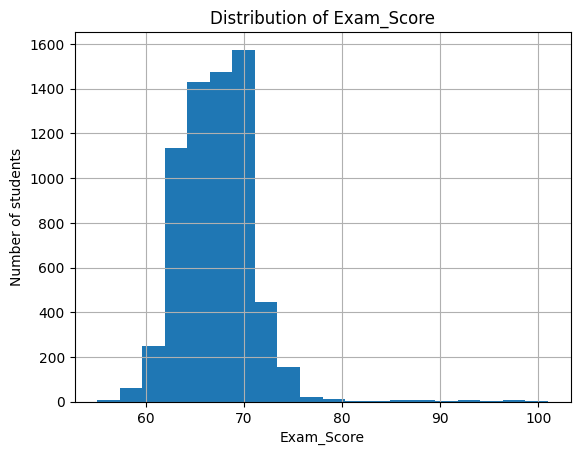

In [9]:
if TARGET in df.columns:
    df[TARGET].hist(bins=20)
    plt.title("Distribution of Exam_Score")
    plt.xlabel("Exam_Score")
    plt.ylabel("Number of students")
    plt.show()
else:
    print(f"Target column {TARGET!r} was not found.")

In [10]:
if TARGET not in df.columns:
    raise ValueError(
        f"Expected target column '{TARGET}' was not found. "
        f"Available columns: {df.columns.tolist()}"
    )

df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df = df.dropna(subset=[TARGET]).reset_index(drop=True)

X = df.drop(columns=[TARGET]).copy()
y = df[TARGET].copy()

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (6607, 19)
Target Shape: (6607,)


### _Enocoding (Oridinal & One-Hot)_

In [11]:
ORDINAL_CATEGORIES = {
    "Parental_Involvement": ["Low", "Medium", "High"],
    "Access_to_Resources": ["Low", "Medium", "High"],
    "Motivation_Level": ["Low", "Medium", "High"],
    "Family_Income": ["Low", "Medium", "High"],
    "Teacher_Quality": ["Low", "Medium", "High"],
    "Peer_Influence": ["Negative", "Neutral", "Positive"],
    "Parental_Education_Level": ["High School", "College", "Postgraduate"],
    "Distance_from_Home": ["Near", "Moderate", "Far"],
}

ordinal_cols = [c for c in ORDINAL_CATEGORIES if c in X.columns]

# Treat remaining object/category/bool columns as nominal.
nominal_cols = [
    c for c in X.columns
    if (pd.api.types.is_object_dtype(X[c])
        or isinstance(X[c].dtype, pd.CategoricalDtype)
        or pd.api.types.is_bool_dtype(X[c]))
    and c not in ordinal_cols
]

numeric_cols = [
    c for c in X.columns
    if c not in ordinal_cols + nominal_cols
]

# Ensure numeric-looking columns are numeric where possible.
for col in numeric_cols:
    X[col] = pd.to_numeric(X[col], errors="coerce")

print("Numeric columns:", numeric_cols)
print("Ordinal columns:", ordinal_cols)
print("Nominal columns:", nominal_cols)

Numeric columns: ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']
Ordinal columns: ['Parental_Involvement', 'Access_to_Resources', 'Motivation_Level', 'Family_Income', 'Teacher_Quality', 'Peer_Influence', 'Parental_Education_Level', 'Distance_from_Home']
Nominal columns: ['Extracurricular_Activities', 'Internet_Access', 'School_Type', 'Learning_Disabilities', 'Gender']


### _Train / validation / test split_

In [12]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

val_fraction_of_remaining = VALIDATION_SIZE / (1 - TEST_SIZE)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=val_fraction_of_remaining,
    random_state=RANDOM_STATE
)

print(f"Train:      {X_train.shape[0]:,} rows ({len(X_train)/len(X):.1%})")
print(f"Validation: {X_val.shape[0]:,} rows ({len(X_val)/len(X):.1%})")
print(f"Test:       {X_test.shape[0]:,} rows ({len(X_test)/len(X):.1%})")

Train:      4,624 rows (70.0%)
Validation: 991 rows (15.0%)
Test:       992 rows (15.0%)


In [13]:
def make_preprocessor():
    transformers = []

    if numeric_cols:
        numeric_pipeline = Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ])
        transformers.append(("numeric", numeric_pipeline, numeric_cols))

    if ordinal_cols:
        ordinal_categories = [ORDINAL_CATEGORIES[c] for c in ordinal_cols]
        ordinal_pipeline = Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OrdinalEncoder(
                categories=ordinal_categories,
                handle_unknown="use_encoded_value",
                unknown_value=-1
            )),
            ("scaler", StandardScaler()),
        ])
        transformers.append(("ordinal", ordinal_pipeline, ordinal_cols))

    if nominal_cols:
        nominal_pipeline = Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore")),
        ])
        transformers.append(("nominal", nominal_pipeline, nominal_cols))

    if not transformers:
        raise ValueError("No usable input features were detected.")

    return ColumnTransformer(
        transformers=transformers,
        remainder="drop",
        verbose_feature_names_out=False
    )

preprocessor = make_preprocessor()

### _Regression models_

In [14]:
def make_models():
    return {
        "Linear Regression": LinearRegression(),
        "Random Forest": RandomForestRegressor(
            n_estimators=400,
            min_samples_leaf=2,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),
        "Extra Trees": ExtraTreesRegressor(
            n_estimators=400,
            min_samples_leaf=2,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),
    }

### _Evaluation metrics_

In [15]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

## Experiment 1 (All Features)

In [16]:
all_features_results = []
all_features_fitted_models = {}

for model_name, estimator in make_models().items():
    pipeline = Pipeline(steps=[
        ("preprocessor", make_preprocessor()),
        ("model", estimator),
    ])
    pipeline.fit(X_train, y_train)
    val_predictions = pipeline.predict(X_val)

    metrics = regression_metrics(y_val, val_predictions)
    all_features_results.append({"Experiment": "All Features Model", "Model": model_name, **metrics})
    all_features_fitted_models[model_name] = pipeline

all_features_results_df = pd.DataFrame(all_features_results).sort_values("RMSE").reset_index(drop=True)
display(all_features_results_df)

best_all_features_name = all_features_results_df.loc[0, "Model"]
best_all_features_model = all_features_fitted_models[best_all_features_name]
print("Best all features model (validation RMSE):", best_all_features_name)

,Experiment,Model,MAE,RMSE,R2
0,All Features Model,Linear Regression,0.452557,1.827041,0.761521
1,All Features Model,Extra Trees,0.955030,2.103374,0.683928
2,All Features Model,Random Forest,1.015049,2.139556,0.672960


Best all features model (validation RMSE): Linear Regression


## Experiment 2 (Model-based Selection)

### _Feature Selection_

In [17]:
selection_preprocessor = make_preprocessor()
X_train_transformed = selection_preprocessor.fit_transform(X_train, y_train)
X_val_transformed = selection_preprocessor.transform(X_val)

transformed_feature_names = selection_preprocessor.get_feature_names_out()

selector_estimator = ExtraTreesRegressor(
    n_estimators=500,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
selector_estimator.fit(X_train_transformed, y_train)

feature_selector = SelectFromModel(
    selector_estimator,
    threshold="median",
    prefit=True
)

X_train_selected = feature_selector.transform(X_train_transformed)
X_val_selected = feature_selector.transform(X_val_transformed)
selected_mask = feature_selector.get_support()
selected_feature_names = transformed_feature_names[selected_mask]

print("Features before selection:", len(transformed_feature_names))
print("Features after selection:", len(selected_feature_names))
print("Selected features:")
for feature in selected_feature_names:
    print(" •", feature)

if X_train_selected.shape[1] == 0:
    raise RuntimeError("Feature selection returned zero features; review the selector threshold.")

Features before selection: 24
Features after selection: 12
Selected features:
 • Hours_Studied
 • Attendance
 • Sleep_Hours
 • Previous_Scores
 • Tutoring_Sessions
 • Physical_Activity
 • Parental_Involvement
 • Access_to_Resources
 • Family_Income
 • Peer_Influence
 • Parental_Education_Level
 • Distance_from_Home


In [18]:
feature_selection_results = []
feature_selection_fitted_models = {}

for model_name, estimator in make_models().items():
    estimator.fit(X_train_selected, y_train)
    val_predictions = estimator.predict(X_val_selected)

    metrics = regression_metrics(y_val, val_predictions)
    feature_selection_results.append({
        "Experiment": "Selected Features Model",
        "Model": model_name,
        **metrics
    })
    feature_selection_fitted_models[model_name] = estimator

feature_selection_results_df = (
    pd.DataFrame(feature_selection_results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)
display(feature_selection_results_df)

best_fs_name = feature_selection_results_df.loc[0, "Model"]
best_fs_estimator = feature_selection_fitted_models[best_fs_name]
print("Best selected features model (validation RMSE):", best_fs_name)

,Experiment,Model,MAE,RMSE,R2
0,Selected Features Model,Linear Regression,0.735184,1.947912,0.728924
1,Selected Features Model,Extra Trees,0.998032,2.136161,0.673998
2,Selected Features Model,Random Forest,1.034051,2.167940,0.664226


Best selected features model (validation RMSE): Linear Regression


## Experiment 3 (Domain-based Feature Selection)

In [19]:
DOMAIN_FEATURES = [
    "Hours_Studied",
    "Attendance",
    "Previous_Scores",
    "Sleep_Hours",
    "Tutoring_Sessions",
    "Motivation_Level",
    "Access_to_Resources",
    "Parental_Involvement",
]

domain_features = [col for col in DOMAIN_FEATURES if col in X.columns]
missing_domain_features = [col for col in DOMAIN_FEATURES if col not in X.columns]

print("Domain-based features used:", domain_features)
if missing_domain_features:
    print("Domain-based features not found in this dataset and skipped:", missing_domain_features)
if not domain_features:
    raise ValueError("None of the configured DOMAIN_FEATURES were found in the dataset.")

# Build a preprocessor for this subset while keeping the same preprocessing rules.
def make_preprocessor_for_columns(feature_columns):
    feature_columns = list(feature_columns)
    selected_numeric_cols = [c for c in numeric_cols if c in feature_columns]
    selected_ordinal_cols = [c for c in ordinal_cols if c in feature_columns]
    selected_nominal_cols = [c for c in nominal_cols if c in feature_columns]
    transformers = []

    if selected_numeric_cols:
        transformers.append(("numeric", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), selected_numeric_cols))

    if selected_ordinal_cols:
        ordinal_categories = [ORDINAL_CATEGORIES[c] for c in selected_ordinal_cols]
        transformers.append(("ordinal", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OrdinalEncoder(
                categories=ordinal_categories,
                handle_unknown="use_encoded_value",
                unknown_value=-1
            )),
            ("scaler", StandardScaler()),
        ]), selected_ordinal_cols))

    if selected_nominal_cols:
        transformers.append(("nominal", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore")),
        ]), selected_nominal_cols))

    if not transformers:
        raise ValueError("No usable domain-based input features were detected.")

    return ColumnTransformer(
        transformers=transformers,
        remainder="drop",
        verbose_feature_names_out=False
    )

Domain-based features used: ['Hours_Studied', 'Attendance', 'Previous_Scores', 'Sleep_Hours', 'Tutoring_Sessions', 'Motivation_Level', 'Access_to_Resources', 'Parental_Involvement']


In [20]:
X_train_domain = X_train[domain_features].copy()
X_val_domain = X_val[domain_features].copy()

domain_results = []
domain_fitted_models = {}

for model_name, estimator in make_models().items():
    pipeline = Pipeline(steps=[
        ("preprocessor", make_preprocessor_for_columns(domain_features)),
        ("model", estimator),
    ])
    pipeline.fit(X_train_domain, y_train)
    val_predictions = pipeline.predict(X_val_domain)

    metrics = regression_metrics(y_val, val_predictions)
    domain_results.append({"Experiment": "Domain Feature Model", "Model": model_name, **metrics})
    domain_fitted_models[model_name] = pipeline

domain_results_df = pd.DataFrame(domain_results).sort_values("RMSE").reset_index(drop=True)
display(domain_results_df)

best_domain_name = domain_results_df.loc[0, "Model"]
best_domain_model = domain_fitted_models[best_domain_name]
print("Best domain feature model (validation RMSE):", best_domain_name)

,Experiment,Model,MAE,RMSE,R2
0,Domain Feature Model,Linear Regression,0.897238,2.055375,0.698189
1,Domain Feature Model,Extra Trees,1.089106,2.212648,0.650234
2,Domain Feature Model,Random Forest,1.104329,2.216274,0.649087


Best domain feature model (validation RMSE): Linear Regression


## Comparison

,Experiment,Model,MAE,RMSE,R2
0,All Features Model,Linear Regression,0.452557,1.827041,0.761521
1,Selected Features Model,Linear Regression,0.735184,1.947912,0.728924
2,Domain Feature Model,Linear Regression,0.897238,2.055375,0.698189
3,All Features Model,Extra Trees,0.955030,2.103374,0.683928
4,Selected Features Model,Extra Trees,0.998032,2.136161,0.673998
5,All Features Model,Random Forest,1.015049,2.139556,0.672960
6,Selected Features Model,Random Forest,1.034051,2.167940,0.664226
7,Domain Feature Model,Extra Trees,1.089106,2.212648,0.650234
8,Domain Feature Model,Random Forest,1.104329,2.216274,0.649087


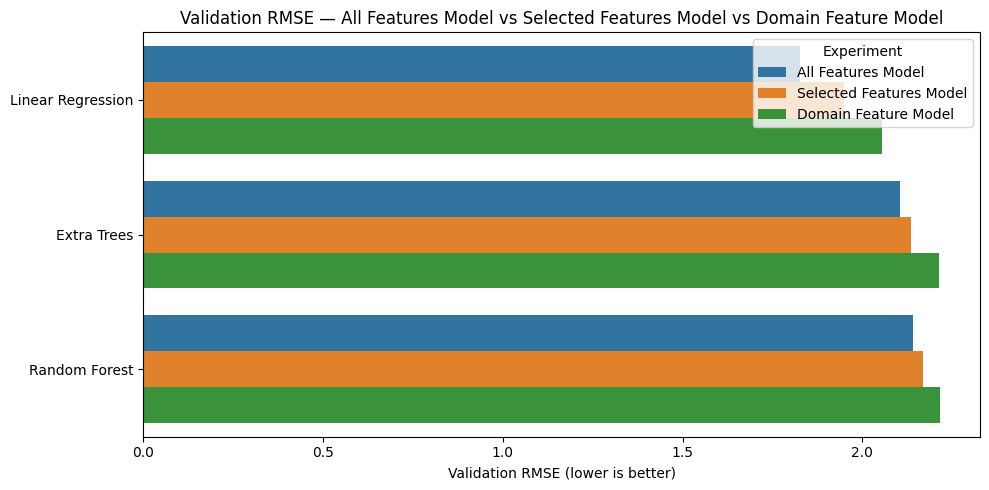

In [21]:
all_validation_results = pd.concat(
    [all_features_results_df, feature_selection_results_df, domain_results_df],
    ignore_index=True
).sort_values("RMSE").reset_index(drop=True)

display(all_validation_results)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=all_validation_results,
    x="RMSE",
    y="Model",
    hue="Experiment"
)
plt.title("Validation RMSE — All Features Model vs Selected Features Model vs Domain Feature Model")
plt.xlabel("Validation RMSE (lower is better)")
plt.ylabel("")
plt.tight_layout()
plt.show()

## Final Test

In [22]:
# Final test predictions for the winning model from each experiment.
all_features_test_predictions = best_all_features_model.predict(X_test)
all_features_test_metrics = regression_metrics(y_test, all_features_test_predictions)

# Transform test data using the preprocessing and selector fitted on training only.
X_test_transformed = selection_preprocessor.transform(X_test)
X_test_selected = feature_selector.transform(X_test_transformed)
fs_test_predictions = best_fs_estimator.predict(X_test_selected)
fs_test_metrics = regression_metrics(y_test, fs_test_predictions)

# Domain-based pipeline was fitted on X_train[domain_features] only.
domain_test_predictions = best_domain_model.predict(X_test[domain_features])
domain_test_metrics = regression_metrics(y_test, domain_test_predictions)

test_results = pd.DataFrame([
    {"Experiment": "All Features Model", "Best Model": best_all_features_name, **all_features_test_metrics},
    {"Experiment": "Selected Features Model", "Best Model": best_fs_name, **fs_test_metrics},
    {"Experiment": "Domain Feature Model", "Best Model": best_domain_name, **domain_test_metrics},
])

display(test_results)

,Experiment,Best Model,MAE,RMSE,R2
0,All Features Model,Linear Regression,0.445060,1.703104,0.797990
1,Selected Features Model,Linear Regression,0.696926,1.833284,0.765927
2,Domain Feature Model,Linear Regression,0.889130,1.923040,0.742446


In [ ]:
feature_selection_bundle = {
    "preprocessor": selection_preprocessor,
    "selector": feature_selector,
    "model": best_fs_estimator,
    "input_columns": X.columns.tolist(),
    "target": TARGET,
    "selected_feature_names": selected_feature_names.tolist(),
    "ordinal_categories": ORDINAL_CATEGORIES,
    "numeric_columns": numeric_cols,
    "ordinal_columns": ordinal_cols,
    "nominal_columns": nominal_cols,
    "validation_best_model": best_fs_name,
    "test_metrics": fs_test_metrics,
}

all_features_bundle = {
    "pipeline": best_all_features_model,
    "input_columns": X.columns.tolist(),
    "target": TARGET,
    "ordinal_categories": ORDINAL_CATEGORIES,
    "numeric_columns": numeric_cols,
    "ordinal_columns": ordinal_cols,
    "nominal_columns": nominal_cols,
    "validation_best_model": best_all_features_name,
    "test_metrics": all_features_test_metrics,
}

all_features_path = MODEL_DIR / "all_features_model.joblib"
feature_selection_path = MODEL_DIR / "selected_features_model.joblib"
domain_path = MODEL_DIR / "domain_feature_model.joblib"

joblib.dump(all_features_bundle, all_features_path)
joblib.dump(feature_selection_bundle, feature_selection_path)

domain_bundle = {
    "pipeline": best_domain_model,
    "input_columns": X.columns.tolist(),
    "domain_features": domain_features,
    "target": TARGET,
    "validation_best_model": best_domain_name,
    "test_metrics": domain_test_metrics,
}
joblib.dump(domain_bundle, domain_path)

print("Saved artifacts:")
print(all_features_path.resolve())
print(feature_selection_path.resolve())
print(domain_path.resolve())

Saved artifacts:
D:\AI 4\First Semester\Data science\Project\RAGentML_DS\models\machine learning models\all_features_model.joblib
D:\AI 4\First Semester\Data science\Project\RAGentML_DS\models\machine learning models\selected_features_model.joblib
D:\AI 4\First Semester\Data science\Project\RAGentML_DS\models\machine learning models\domain_feature_model.joblib
